# Arabic Fake News Detection — Fine-tuning AraBERT

**Goal:** fine-tune `aubmindlab/bert-base-arabertv02` as a binary classifier that separates
real Arabic news articles from fake ones.

**Data:** `fake_news_dataset_10k.json` (label = 1) and `real_news_dataset_10k.json` (label = 0),
~10,000 articles each, ~20,000 articles total.

**Why AraBERT instead of XLM-RoBERTa?** XLM-R is multilingual (100 languages) so its capacity is
shared across all of them. AraBERT is a BERT model pretrained **only on Arabic** (news, Wikipedia,
OSIAN, 1.5B words…), with a vocabulary built for Arabic. On Arabic news it is therefore often as
good or better than XLM-R while being lighter (~135M parameters vs ~278M) and faster to train.
The price to pay: AraBERT expects a **specific text preprocessing** (Section 3bis) — skipping it
is the most common reason for disappointing AraBERT results.

**How to use this notebook:** run the cells in order from top to bottom. Each section starts with a
short explanation of *what* we are doing and *why*. The final chapter,
**"Understanding Every Line of the Fine-tuning Code"**, revisits the key code blocks line by line.

The structure is intentionally identical to the XLM-R notebook so the two results can be compared fairly
(same data, same split, same seed, same hyperparameters).

---

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Section 1 — Libraries

Five families of tools:

- **Data handling:** `pandas`, `numpy`, `json`.
- **Modeling:** `transformers`, `torch` — load AraBERT, tokenize, train with the Hugging Face `Trainer`.
- **Arabic preprocessing:** `arabert` — provides `ArabertPreprocessor`, the official cleaning pipeline
  matching how AraBERT was pretrained.
- **Splitting & metrics:** `scikit-learn`.
- **Visualization:** `matplotlib`, `seaborn`.

In [3]:
# Run once. --quiet keeps the output short.
!pip install -q --break-system-packages transformers datasets torch scikit-learn pandas numpy matplotlib seaborn accelerate arabert

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 7.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 14.5 MB/s eta 0:00:00


In [4]:
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc, classification_report
)

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback
)
from arabert.preprocess import ArabertPreprocessor

# Reproducibility: same seed as the XLM-R notebook, so the split is identical.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


## Section 2 — Load

We load the two raw JSON files into pandas DataFrames. Labels are attached in Section 3.

In [8]:
with open("/content/drive/MyDrive/fake_news_dataset_10k_final.json", "r", encoding="utf-8") as f:
    fake_data = json.load(f)
    fake_raw = fake_data.get('articles', [])

with open("/content/drive/MyDrive/Real_news_dataset_10k_final.json", "r", encoding="utf-8") as f:
    real_data = json.load(f)
    real_raw = real_data.get('articles', [])

print(f"Fake articles loaded: {len(fake_raw)}")
print(f"Real articles loaded: {len(real_raw)}")
print("\nSample fake record:")
print(fake_raw[0] if fake_raw else "No data")

Fake articles loaded: 10000
Real articles loaded: 10000

Sample fake record:
{'published_date': '2021-03-17', 'title': 'ضبط 65 حالة غش في امتحانات جامعة جنوب الوادي', 'text': 'أحال الدكتور عباس منصور رئيس جامعة جنوب 65 طالب بالجامعة لمجلس التأديب لضبطهم متلبسين بالغش اثناء اداء امتحانات الفصل الدراسي الثاني للعام الجامعي 2016 / 2017 .\nوتبين أن الطلاب استخدموا وسائل غش مختلفة من ورق خارجي ومساطر واستخدام سماعات الهاتف المحمول.\nوجاءت حالات الغش على النحو التالي ( 36 ) حالة غش بكلية الآداب و ( 16 ) حالة بكلية الحقوق و ( 8 ) بكلية التربية بقنا وحالتان بكلية التمريض وحالتان بكلية التربية النوعية وحالة واحدة بكلية الاعلام وتكنولوجيا الاتصال.\nومن جانبه أكد الدكتور محمد أبو الفضل بدران نائب رئيس الجامعة لشئون التعليم والطلاب أن الامتحانات بكليات الجامعة وفروعها بالأقصر والغردقة سجلت هدوءا ملحوظا وتسير وفق قواعد واجراءات الامتحانات مع مراعاة توفير الاجواء المناسبة للطلاب لأداء امتحاناتهم.\nولفت إلى أن الجامعة وفرت كل وسائل الراحة للطلاب داخل اللجان وأن الكنترولات تباشر اعمالها اولا بأول في ا

In [9]:
df_fake = pd.DataFrame(fake_raw)
df_real = pd.DataFrame(real_raw)

print("Fake dataframe columns:", list(df_fake.columns))
print("Real dataframe columns:", list(df_real.columns))
df_fake.head(3)

Fake dataframe columns: ['published_date', 'title', 'text', 'category', 'category_score', 'matched_keywords', 'label']
Real dataframe columns: ['published_date', 'title', 'text', 'label', 'category', 'category_score', 'matched_keywords']


,published_date,title,text,category,category_score,matched_keywords,label
0,2021-03-17,ضبط 65 حالة غش في امتحانات جامعة جنوب الوادي,أحال الدكتور عباس منصور رئيس جامعة جنوب 65 طال...,Education,39,"[تعليم, التعليم, تربية, التربية, جامعة, كلية, ...",Fake
1,2021-03-04,عبيدات: الشركات المصنعة للقاح أخلت مسؤوليتها م...,رؤيا نيوز- قال وزير الصحة نذير عبيدات، إن الشر...,Health,15,"[الصحة, كورونا, لقاح, تطعيم, دواء, علاج, لقاحات]",Fake
2,2021-04-10,عثمان بطيخ: حكم إفطار رمضان لمرضى كورونا والطا...,أكد مفتي الديار التونسية عثمان بطيخ أنه يحق لم...,Health,14,"[مرض, مرضى, كورونا, فيروس, تلقيح, مناعة]",Fake


> **Note:** if your JSON uses a different text field name than `text`, change `TEXT_COL` below —
> every later cell reads from it.

In [10]:
TEXT_COL = "text"   # <-- change this if your JSON field has a different name

assert TEXT_COL in df_fake.columns, f"'{TEXT_COL}' not found in fake dataset columns: {list(df_fake.columns)}"
assert TEXT_COL in df_real.columns, f"'{TEXT_COL}' not found in real dataset columns: {list(df_real.columns)}"

## Section 3 — Merge Datasets

```
Fake  ──►  label = 1
Real  ──►  label = 0
```

Convention: **1 = fake**, because the "positive class" is the thing we want to *catch*, which makes
precision/recall read naturally. After labeling, we concatenate and shuffle so the model never sees a
long run of only-fake or only-real examples.

In [11]:
df_fake["label"] = 1   # fake
df_real["label"] = 0   # real

df = pd.concat([df_fake[[TEXT_COL, "label"]], df_real[[TEXT_COL, "label"]]], ignore_index=True)
df = df.rename(columns={TEXT_COL: "text"})

# Drop empty / null articles
before = len(df)
df = df[df["text"].notna() & (df["text"].str.strip().str.len() > 0)].reset_index(drop=True)
print(f"Dropped {before - len(df)} empty/null rows")

# Shuffle (same random_state as the XLM-R notebook)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Total articles: {len(df)}")
print(df["label"].value_counts().rename({0: "real (0)", 1: "fake (1)"}))
df.head(3)

Dropped 0 empty/null rows
Total articles: 20000
label
real (0)    10000
fake (1)    10000
Name: count, dtype: int64


,text,label
0,كتب : ياسمين عزت\nفي منطقة سعدون بقلب مدينة بل...,0
1,قدرت وزارة الصناعة السورية حجم الأضرار التي طا...,1
2,صحافي:لن ننتصر على الإمامة إليوم إلا بالإنتصار...,1


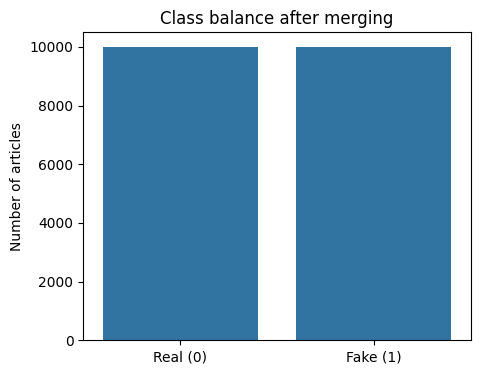

In [12]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="label")
plt.xticks([0, 1], ["Real (0)", "Fake (1)"])
plt.title("Class balance after merging")
plt.ylabel("Number of articles")
plt.xlabel("")
plt.show()

## Section 3bis — AraBERT-specific Preprocessing (new compared to XLM-R)

XLM-R's SentencePiece tokenizer is trained to digest raw text. **AraBERT is not**: it was pretrained
on text that had been normalized in a specific way, so we must reproduce that normalization.
`ArabertPreprocessor` (given the model name) applies, among other things:

- removal of **tatweel** (the elongation character, e.g. `الــــسلام`),
- normalization of **Arabic/Persian digits and punctuation**,
- insertion of spaces around digits, Latin letters and punctuation so they tokenize cleanly,
- removal of repeated characters and of most **diacritics (tashkeel)**,
- removal of HTML tags, URLs/emails/mentions handling, and whitespace cleanup.

For the `v02` models **no Farasa segmentation is needed** (that was only required for AraBERT v1),
so there is no Java dependency and preprocessing 20k articles takes a few seconds.

**Why preprocess before the train/val/test split?** The transformation is deterministic and
row-wise (it learns nothing from the data), so it cannot leak information between splits.

> Remember to apply **exactly the same preprocessing at inference time** (Sections 11 and 12).

In [13]:
MODEL_NAME = "aubmindlab/bert-base-arabertv02"

arabert_prep = ArabertPreprocessor(model_name=MODEL_NAME)

# Show the effect on one article
raw_example = df.iloc[0]["text"]
print("RAW   :", raw_example[:300].replace("\n", " "))
print()
print("CLEAN :", arabert_prep.preprocess(raw_example)[:300].replace("\n", " "))

RAW   : كتب : ياسمين عزت في منطقة سعدون بقلب مدينة بلبيس التابعة لمحافظة الشرقية، وتحديدّا في شارع البايض، حيث جريمة القتل البشعة للطفل "خالد" الذي لم يتجاوز عمره 3 أشهر على يد والدته، والتي وقعت صباح الخميس الماضي من الشهر الجاري، والتي مازالت حديث الشارع الشرقاوي، والشارع المصري بشكل عام، حيث اكتُشفت الوا

CLEAN : كتب : ياسمين عزت في منطقة سعدون بقلب مدينة بلبيس التابعة لمحافظة الشرقية ، وتحديدا في شارع البايض ، حيث جريمة القتل البشعة للطفل " خالد " الذي لم يتجاوز عمره 3 أشهر على يد والدته ، والتي وقعت صباح الخميس الماضي من الشهر الجاري ، والتي مازالت حديث الشارع الشرقاوي ، والشارع المصري بشكل عام ، حيث اكتشف


In [14]:
# Apply to the whole dataset (keep the raw text for error analysis later)
df["text_raw"] = df["text"]
df["text"] = df["text_raw"].apply(arabert_prep.preprocess)

# Safety: preprocessing could in theory empty an article
before = len(df)
df = df[df["text"].str.strip().str.len() > 0].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows emptied by preprocessing | Total: {len(df)}")

Dropped 0 rows emptied by preprocessing | Total: 20000


## Section 4 — Train / Validation / Test Split

```
Train : 80%     Val : 10%     Test : 10%
```

Same reasoning as in the XLM-R notebook: with ~20,000 articles, 2,000 examples in validation and test
already give stable metrics (95% CI of about ±1.5–2 points), while every extra training example keeps
paying off for a transformer. **Stratified** splitting preserves the 50/50 fake/real ratio in each split.

Because we use the same `SEED` and the same shuffle, the **test set contains the same articles as in the
XLM-R notebook** — results are directly comparable.

In [15]:
train_val_df, test_df = train_test_split(
    df, test_size=0.10, stratify=df["label"], random_state=SEED,
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.10 / 0.90, stratify=train_val_df["label"], random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train: {len(train_df):>6} ({len(train_df)/len(df):.1%})")
print(f"Val:   {len(val_df):>6} ({len(val_df)/len(df):.1%})")
print(f"Test:  {len(test_df):>6} ({len(test_df)/len(df):.1%})")

for name, split in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{name:>6} fake ratio: {split['label'].mean():.3f}")

Train:  15999 (80.0%)
Val:     2001 (10.0%)
Test:    2000 (10.0%)
 Train fake ratio: 0.500
   Val fake ratio: 0.500
  Test fake ratio: 0.500


## Section 5 — Load Tokenizer

AraBERT uses a **WordPiece** vocabulary (64k tokens), trained on Arabic. Compared with XLM-R's
250k-token multilingual SentencePiece vocabulary, Arabic words are usually split into **fewer, more
meaningful pieces** (AraBERT v02 also keeps frequent clitics like `ال`, `و`, `ب` as separate `+` pieces),
so the same article uses fewer tokens — a 256-token window covers more text.

In [16]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(type(tokenizer))
print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"CLS token: {tokenizer.cls_token} (id={tokenizer.cls_token_id})")
print(f"SEP token: {tokenizer.sep_token} (id={tokenizer.sep_token_id})")
print(f"PAD token: {tokenizer.pad_token} (id={tokenizer.pad_token_id})")
print(f"UNK token: {tokenizer.unk_token} (id={tokenizer.unk_token_id})")
print(f"Model max length: {tokenizer.model_max_length}")

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/825k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

<class 'transformers.models.bert.tokenization_bert.BertTokenizer'>
Vocabulary size: 64000
CLS token: [CLS] (id=2)
SEP token: [SEP] (id=3)
PAD token: [PAD] (id=0)
UNK token: [UNK] (id=1)
Model max length: 512


- `MODEL_NAME` — pins the exact checkpoint, defined once and reused by the preprocessor, tokenizer and model.
- `AutoTokenizer.from_pretrained(...)` — loads the vocabulary of **this** checkpoint. The tokenizer must
  always match the model; mixing them silently scrambles token IDs.
- `[CLS]` is prepended to every sequence — its final hidden state feeds the classification head.
- `[SEP]` marks the end of a sequence.
- `[PAD]` fills shorter sequences up to a fixed length inside a batch.
- `[UNK]` is the fallback for unknown pieces (rare with WordPiece).
- Difference with XLM-R: special tokens are `[CLS]/[SEP]/[PAD]/[UNK]` (BERT style) instead of
  `<s>/</s>/<pad>/<unk>` (RoBERTa style), and the BERT tokenizer also returns `token_type_ids`
  (all zeros here, since we classify single texts).

## Section 6 — Tokenization

Pipeline on a **real article from your dataset**:

```
Sentence  ─►  Tokens  ─►  IDs  ─►  Attention Mask
```

In [17]:
sample_text = train_df.iloc[0]["text"]
sample_label = train_df.iloc[0]["label"]

print("Preprocessed sentence (truncated to 200 chars):")
print(sample_text[:200], "...")
print(f"\nTrue label: {'fake' if sample_label == 1 else 'real'}")

Preprocessed sentence (truncated to 200 chars):
موقع الوحدة الاخباري نقدم لكم اخر المستجدات على الساحة العربية والعالمية واخر الاخبار لحظة وقوعها اخر الاخبار الرياضية والعربية والعالمية والاخبار المنوعة كما ونقدم لكم حصادنا الاخباري لجميع الدول الع ...

True label: fake


In [18]:
# Step 1: Sentence -> Tokens (WordPiece pieces; "##" marks a continuation piece)
tokens = tokenizer.tokenize(sample_text)
print("Step 1 — Tokens (first 20):")
print(tokens[:20])

Step 1 — Tokens (first 20):
['موقع', 'الوحدة', 'الاخبار', '##ي', 'نقدم', 'لكم', 'اخر', 'المستجدات', 'على', 'الساحة', 'العربية', 'والعالمية', 'واخر', 'الاخبار', 'لحظة', 'وقوعها', 'اخر', 'الاخبار', 'الرياضية', 'والعربية']


In [19]:
# Step 2: Tokens -> IDs
ids = tokenizer.convert_tokens_to_ids(tokens)
print("Step 2 — Token IDs (first 20):")
print(ids[:20])

Step 2 — Token IDs (first 20):
[1779, 2994, 21783, 193, 14216, 6796, 6210, 13431, 323, 4469, 773, 14411, 44374, 21783, 5657, 34355, 6210, 21783, 2976, 10153]


In [20]:
# Step 3: Full encoding as fed to the model
MAX_LEN = 256  # justified below

encoded = tokenizer(
    sample_text,
    max_length=MAX_LEN,
    padding="max_length",
    truncation=True,
    return_tensors="pt",
)

print("Step 3 — input_ids (first 20):", encoded["input_ids"][0][:20].tolist())
print("Step 3 — attention_mask (first 20):", encoded["attention_mask"][0][:20].tolist())
print("Step 3 — token_type_ids (first 20):", encoded["token_type_ids"][0][:20].tolist())
print(f"\ninput_ids shape: {encoded['input_ids'].shape}")

print("\nDecoded back to text (sanity check):")
print(tokenizer.decode(encoded["input_ids"][0][:20]))

Step 3 — input_ids (first 20): [2, 1779, 2994, 21783, 193, 14216, 6796, 6210, 13431, 323, 4469, 773, 14411, 44374, 21783, 5657, 34355, 6210, 21783, 2976]
Step 3 — attention_mask (first 20): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Step 3 — token_type_ids (first 20): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

input_ids shape: torch.Size([1, 256])

Decoded back to text (sanity check):
[CLS] موقع الوحدة الاخباري نقدم لكم اخر المستجدات على الساحة العربية والعالمية واخر الاخبار لحظة وقوعها اخر الاخبار الرياضية


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (987 > 512). Running this sequence through the model will result in indexing errors


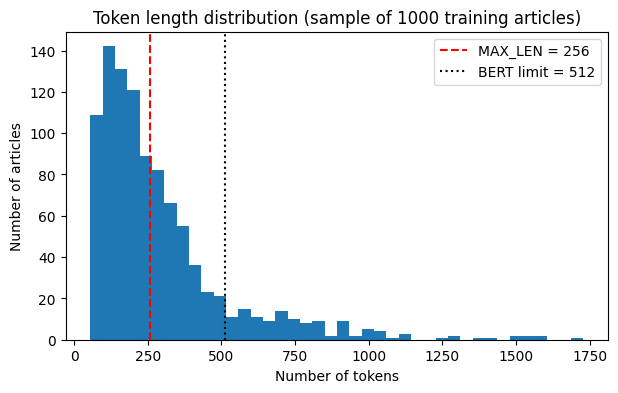

Truncated at 256 tokens: 42.2%
Truncated at 512 tokens: 12.6%
Median length: 222 tokens


In [21]:
# Choose MAX_LEN from the real token-length distribution.
# (BERT's hard limit is 512 positions; the "longer than 512" warning here is harmless since we only count.)
sample_lengths = [len(tokenizer.encode(t, truncation=False)) for t in train_df["text"].sample(1000, random_state=SEED)]

plt.figure(figsize=(7, 4))
plt.hist(sample_lengths, bins=40)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.axvline(512, color="black", linestyle=":", label="BERT limit = 512")
plt.title("Token length distribution (sample of 1000 training articles)")
plt.xlabel("Number of tokens")
plt.ylabel("Number of articles")
plt.legend()
plt.show()

lengths = np.array(sample_lengths)
print(f"Truncated at {MAX_LEN} tokens: {(lengths > MAX_LEN).mean():.1%}")
print(f"Truncated at 512 tokens: {(lengths > 512).mean():.1%}")
print(f"Median length: {int(np.median(lengths))} tokens")

Adjust `MAX_LEN` based on the histogram:
- With XLM-R, 62.8% of articles were truncated at 256 tokens. AraBERT's Arabic-specific vocabulary
  usually produces fewer tokens per article, so the truncation rate should be lower here.
- If it is still high, consider `MAX_LEN = 384` or `512` (the maximum for BERT) at the cost of slower training
  and more GPU memory. Since the whole 256→512 range is available, this is a cheap experiment to run
  once the baseline is trained. For a fair comparison with XLM-R, keep 256 for the first run.

## Section 7 — Load AraBERT

`aubmindlab/bert-base-arabertv02` is a pretrained BERT encoder (12 layers, 768 hidden, ~135M parameters).
`AutoModelForSequenceClassification` attaches a **classification head** on top:

```
[Pretrained AraBERT encoder]
              │
     hidden state of [CLS]
              │
   BERT pooler: Linear(768→768) + tanh      ← pretrained (next-sentence-prediction objective)
              │
           Dropout
              │
      Linear layer (768 → 2)                ← randomly initialized
              │
           logits (real-score, fake-score)
```

Difference with XLM-R: BERT reuses its **pretrained pooler** (dense + tanh on `[CLS]`) and adds only one
new linear layer, whereas the RoBERTa head used for XLM-R builds a new dense + tanh + linear stack from scratch.
So AraBERT starts fine-tuning with slightly more pretrained structure in its head.

In [22]:
LABEL2ID = {"real": 0, "fake": 1}
ID2LABEL = {0: "real", 1: "fake"}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)
model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters:     135,194,882
Trainable parameters: 135,194,882


> A warning like *"Some weights of BertForSequenceClassification were not initialized from the model
> checkpoint: classifier.weight, classifier.bias"* is expected: it is exactly the new classification layer
> described above. Training in Section 8 is what teaches it.

## Section 8 — Training

We wrap the DataFrames in a PyTorch `Dataset`, then configure every hyperparameter with the reason for its value.

In [23]:
class NewsDataset(Dataset):
    """Wraps a DataFrame of (text, label) pairs and tokenizes lazily, one example at a time.
    Lazy tokenization keeps memory usage flat regardless of dataset size."""

    def __init__(self, dataframe, tokenizer, max_len):
        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["label"].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


train_dataset = NewsDataset(train_df, tokenizer, MAX_LEN)
val_dataset = NewsDataset(val_df, tokenizer, MAX_LEN)
test_dataset = NewsDataset(test_df, tokenizer, MAX_LEN)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Val dataset size:   {len(val_dataset)}")
print(f"Test dataset size:  {len(test_dataset)}")

Train dataset size: 15999
Val dataset size:   2001
Test dataset size:  2000


In [24]:
def compute_metrics(eval_pred):
    """Called by the Trainer after every evaluation pass (end of each epoch)."""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="binary", pos_label=1
    )
    acc = accuracy_score(labels, predictions)
    return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}

### Hyperparameters — what and why

We keep **exactly the same values as in the XLM-R notebook** so the comparison isolates the effect of the model.

| Hyperparameter | Value | Why this value |
|---|---|---|
| `num_train_epochs` | **4** | Fine-tuning converges in 2–5 passes; more risks overfitting ~16k examples. Early stopping + `load_best_model_at_end` protect us. |
| `learning_rate` | **2e-5** | Standard range (1e-5 to 5e-5) for BERT-family fine-tuning. The original AraBERT paper uses values in this range. |
| `weight_decay` | **0.01** | Mild L2 regularization, standard in BERT recipes. |
| `per_device_train_batch_size` | **16** | AraBERT-base (135M) at length 256 fits easily on a 16 GB T4; it uses less memory than XLM-R-base, so you could even go to 32. |
| `gradient_accumulation_steps` | **2** | Effective batch of 32, a stable size for BERT fine-tuning. |
| `warmup_steps` | **6% of total steps** | Linear ramp-up of the learning rate so the randomly initialized classifier layer settles before full-size updates. Computed from the data (`warmup_ratio` is deprecated in recent `transformers`). |
| `eval_strategy` / `save_strategy` | **"epoch"** | Evaluate and checkpoint once per epoch; both must match for `load_best_model_at_end`. |
| `load_best_model_at_end` | **True** | Reload the checkpoint with the best validation F1, not simply the last epoch. |
| `metric_for_best_model` | **"f1"** | Balances false positives and false negatives, which both matter for fake-news detection. |

In [28]:
OUTPUT_DIR = "/content/drive/MyDrive/arabert-fake-news-checkpoints"

# 6% warmup, expressed in optimizer steps
EPOCHS = 4
BATCH_SIZE = 16
GRAD_ACCUM = 2
steps_per_epoch = int(np.ceil(len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM)))
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(0.06 * total_steps)
print(f"steps/epoch={steps_per_epoch} | total steps={total_steps} | warmup steps={warmup_steps}")

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    learning_rate=2e-5,
    weight_decay=0.01,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=GRAD_ACCUM,
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

steps/epoch=500 | total steps=2000 | warmup steps=120


`EarlyStoppingCallback(early_stopping_patience=2)` stops training if validation F1 doesn't improve for
2 consecutive evaluations.

> **Colab tip:** the XLM-R run was interrupted at epoch 2 (a `KeyboardInterrupt` while saving a checkpoint).
> To avoid losing progress if the runtime disconnects, point `OUTPUT_DIR` to Google Drive
> (e.g. `/content/drive/MyDrive/arabert-fake-news-checkpoints`) and resume with
> `trainer.train(resume_from_checkpoint=True)`.

In [29]:
train_result = trainer.train()

print("\nTraining complete.")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.572257,0.254924,0.879560,0.894081,0.861000,0.877229
2,0.447352,0.242430,0.887056,0.901452,0.869000,0.884929
3,0.300337,0.265699,0.899550,0.887488,0.915000,0.901034
4,0.231503,0.304192,0.896552,0.893744,0.900000,0.896861


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training complete.
{'train_runtime': 1071.8532, 'train_samples_per_second': 59.706, 'train_steps_per_second': 1.866, 'total_flos': 8419027549409280.0, 'train_loss': 0.3780510897636414, 'epoch': 4.0}


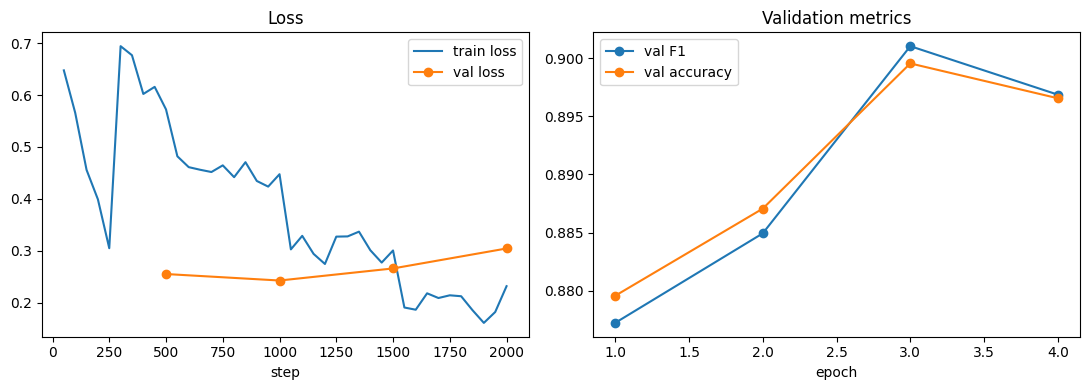

In [31]:
# Training / validation curves
log = pd.DataFrame(trainer.state.log_history)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
train_log = log[log["loss"].notna()] if "loss" in log else pd.DataFrame()
eval_log = log[log["eval_loss"].notna()] if "eval_loss" in log else pd.DataFrame()

if not train_log.empty:
    ax[0].plot(train_log["step"], train_log["loss"], label="train loss")
if not eval_log.empty:
    ax[0].plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="val loss")
ax[0].set_title("Loss"); ax[0].set_xlabel("step"); ax[0].legend()

if not eval_log.empty:
    ax[1].plot(eval_log["epoch"], eval_log["eval_f1"], marker="o", label="val F1")
    ax[1].plot(eval_log["epoch"], eval_log["eval_accuracy"], marker="o", label="val accuracy")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

## Section 9 — Evaluation

We evaluate on the **test set** (never touched during training or hyperparameter choices).

In [32]:
predictions_output = trainer.predict(test_dataset)
logits = predictions_output.predictions
y_true = predictions_output.label_ids
y_pred = np.argmax(logits, axis=1)

# Softmax -> probabilities (needed for ROC / AUC and threshold tuning)
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
y_score = probs[:, 1]   # probability of the "fake" class

In [33]:
acc = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {precision:.4f}  (of articles predicted fake, how many really were)")
print(f"Recall:    {recall:.4f}  (of articles that really were fake, how many we caught)")
print(f"F1-score:  {f1:.4f}  (harmonic mean of precision and recall)")

Accuracy:  0.8800
Precision: 0.8770  (of articles predicted fake, how many really were)
Recall:    0.8840  (of articles that really were fake, how many we caught)
F1-score:  0.8805  (harmonic mean of precision and recall)


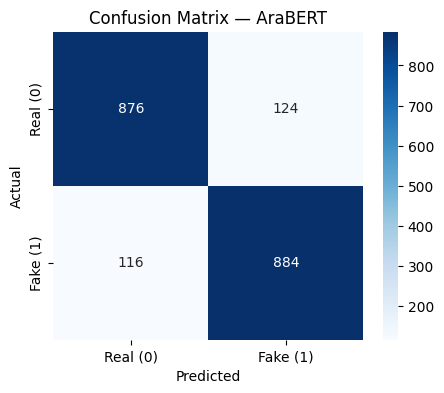

True Negatives  (real correctly kept):   876
False Positives (real flagged as fake):  124
False Negatives (fake missed as real):   116
True Positives  (fake correctly caught): 884


In [34]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real (0)", "Fake (1)"],
            yticklabels=["Real (0)", "Fake (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — AraBERT")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (real correctly kept):   {tn}")
print(f"False Positives (real flagged as fake):  {fp}")
print(f"False Negatives (fake missed as real):   {fn}")
print(f"True Positives  (fake correctly caught): {tp}")

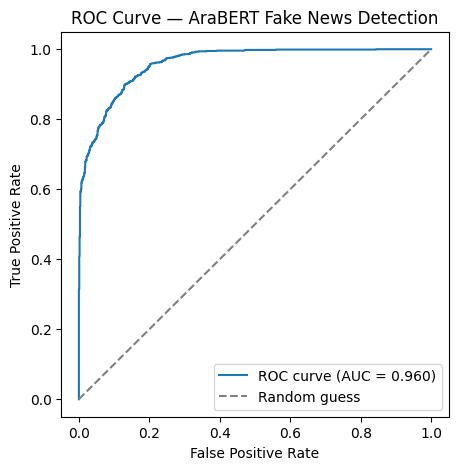

AUC: 0.9602


In [35]:
fpr, tpr, thresholds_roc = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — AraBERT Fake News Detection")
plt.legend()
plt.show()

print(f"AUC: {roc_auc:.4f}")

In [36]:
print(classification_report(y_true, y_pred, target_names=["real", "fake"]))

              precision    recall  f1-score   support

        real       0.88      0.88      0.88      1000
        fake       0.88      0.88      0.88      1000

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



### Decision-threshold optimisation
By default `argmax` uses a 0.5 threshold. We scan other thresholds on the **validation set** (not the test
set, to avoid tuning on the data we report on), then report the test score at that chosen threshold.

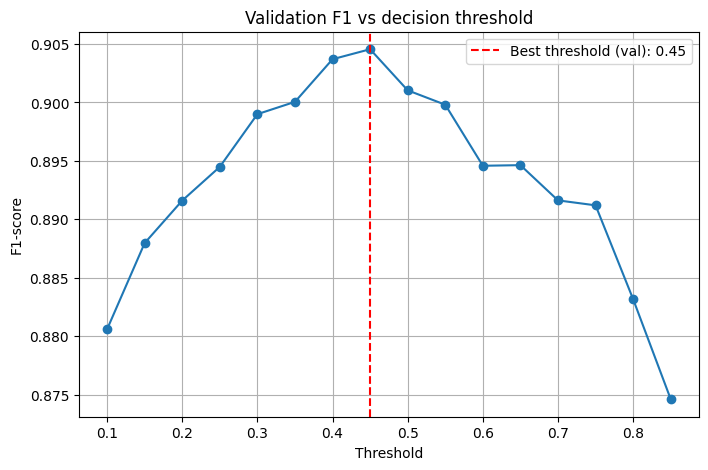

Best threshold (chosen on validation): 0.45
Test @0.50 -> F1 = 0.8805
Test @0.45 -> precision = 0.8721 | recall = 0.9000 | F1 = 0.8858


In [37]:
# 1) Probabilities on the validation set
val_out = trainer.predict(val_dataset)
val_scores = torch.softmax(torch.tensor(val_out.predictions), dim=1).numpy()[:, 1]
val_true = val_out.label_ids

# 2) Scan thresholds on validation
thresholds = np.arange(0.1, 0.9, 0.05)
val_f1 = []
for t in thresholds:
    _, _, f1_t, _ = precision_recall_fscore_support(val_true, (val_scores >= t).astype(int), average="binary", zero_division=0)
    val_f1.append(f1_t)

best_threshold = float(thresholds[int(np.argmax(val_f1))])

plt.figure(figsize=(8, 5))
plt.plot(thresholds, val_f1, marker="o")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold (val): {best_threshold:.2f}")
plt.title("Validation F1 vs decision threshold")
plt.xlabel("Threshold"); plt.ylabel("F1-score")
plt.legend(); plt.grid(True); plt.show()

# 3) Report on the test set at that threshold
y_pred_thr = (y_score >= best_threshold).astype(int)
p_t, r_t, f_t, _ = precision_recall_fscore_support(y_true, y_pred_thr, average="binary", zero_division=0)
print(f"Best threshold (chosen on validation): {best_threshold:.2f}")
print(f"Test @0.50 -> F1 = {f1:.4f}")
print(f"Test @{best_threshold:.2f} -> precision = {p_t:.4f} | recall = {r_t:.4f} | F1 = {f_t:.4f}")

### Error analysis
Articles where the model is most confident **and** wrong. We display the *raw* text (before preprocessing)
to read them naturally.

In [38]:
test_results = test_df.copy()
test_results["prob_fake"] = y_score
test_results["prediction"] = y_pred
cols = ["text_raw", "label", "prob_fake", "prediction"]

print("--- Top False Positives (real predicted as fake) ---")
display(test_results[(test_results["label"] == 0) & (test_results["prediction"] == 1)]
        .sort_values("prob_fake", ascending=False).head(5)[cols])

print("\n--- Top False Negatives (fake predicted as real) ---")
display(test_results[(test_results["label"] == 1) & (test_results["prediction"] == 0)]
        .sort_values("prob_fake", ascending=True).head(5)[cols])

--- Top False Positives (real predicted as fake) ---


,text_raw,label,prob_fake,prediction
1468,- مدبولى: علاقات الدولتين نموذج في علاقات الأخ...,0,0.997654,1
1357,تمكن عناصر فرقة البحث والتدخل BRI التابعة للمص...,0,0.995272,1
92,أعلن وزير الصناعة السوداني إبراهيم الشيخ، السب...,0,0.993855,1
319,كشف ديوان المحاسبة في تقريره للعام 2019، أن جم...,0,0.989977,1
1736,"ورد أن وزير الخارجية الألماني يعتقد أنه من ""ال...",0,0.986125,1



--- Top False Negatives (fake predicted as real) ---


,text_raw,label,prob_fake,prediction
1608,أميرة امكيدش / الاتحاد: أكد وزير العدل حافظ ال...,1,0.001882,0
1717,الدوحة - أ ف ب - جزم رئيس الاتحاد الدولي للسبا...,1,0.004174,0
997,شدد أعضاء فى مجلس النواب، على ضرورة رقابة الدو...,1,0.005501,0
848,في ظل تسليم رئيس الحكومة الليبية عبد الحميد ال...,1,0.005566,0
837,الطلب على الفستان ازداد بعد عرضه، ووصف البعض ا...,1,0.008933,0


### Comparing with XLM-R

Fill in this table with your XLM-R numbers to see the effect of the model alone
(same data, same test articles, same hyperparameters):

| Metric | XLM-R base (reference run) | AraBERT v02 (this run) |
|---|---|---|
| Accuracy | 0.8530 | *see above* |
| Precision (fake) | 0.8091 | *see above* |
| Recall (fake) | 0.9240 | *see above* |
| F1 (fake) | 0.8627 | *see above* |
| AUC | 0.9417 | *see above* |

Remember that a difference of ~1 point on 2,000 test examples is within the statistical noise
(≈ ±1.5–2 points); only larger gaps, or a consistent gap across several seeds, are conclusive.

### Interpreting the results

- **Accuracy** is overall correctness; read it alongside precision/recall.
- **Precision on "fake"**: when the model says fake, can I trust it? Low precision means real articles get wrongly flagged.
- **Recall on "fake"**: of all fake articles, how many are caught? Low recall means misinformation slips through.
- **F1** balances both; always check the confusion matrix too.
- **AUC** measures how well the fake-probability *ranks* fake above real across all thresholds; a high AUC with a
  mediocre F1 suggests the 0.5 cutoff is not ideal (see threshold optimisation).

## Section 10 — Save

We persist what is needed to reuse the model independently of this notebook:

1. **Model weights**
2. **Tokenizer**
3. **Label mapping**
4. **Preprocessing config** (the AraBERT model name used by `ArabertPreprocessor`) and the chosen
   `max_len` / decision threshold — **new for AraBERT**, because inference must reproduce the exact preprocessing used in training.

In [39]:
SAVE_DIR = "/content/drive/MyDrive/arabert-fake-news-final"

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

label_mapping = {"id2label": ID2LABEL, "label2id": LABEL2ID}
with open(f"{SAVE_DIR}/label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(label_mapping, f, ensure_ascii=False, indent=2)

inference_config = {
    "arabert_preprocessor_model": MODEL_NAME,
    "max_len": MAX_LEN,
    "decision_threshold": best_threshold,
}
with open(f"{SAVE_DIR}/inference_config.json", "w", encoding="utf-8") as f:
    json.dump(inference_config, f, indent=2)

print(f"Saved model, tokenizer, label mapping and inference config to: {SAVE_DIR}")
import os
print(os.listdir(SAVE_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model, tokenizer, label mapping and inference config to: /content/drive/MyDrive/arabert-fake-news-final
['config.json', 'model.safetensors', 'training_args.bin', 'tokenizer_config.json', 'tokenizer.json', 'label_mapping.json', 'inference_config.json']


## Section 11 — Inference

We reload from disk (proving the saved artifacts are self-contained) and classify articles.
**Raw text goes through `ArabertPreprocessor` first**, exactly as in training.

In [40]:
inference_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
inference_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)
inference_model.to(DEVICE)
inference_model.eval()

with open(f"{SAVE_DIR}/label_mapping.json", "r", encoding="utf-8") as f:
    ID2LABEL_LOADED = {int(k): v for k, v in json.load(f)["id2label"].items()}

with open(f"{SAVE_DIR}/inference_config.json", "r", encoding="utf-8") as f:
    INF_CFG = json.load(f)

inference_prep = ArabertPreprocessor(model_name=INF_CFG["arabert_preprocessor_model"])

print("Model reloaded. Label mapping:", ID2LABEL_LOADED)
print("Inference config:", INF_CFG)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model reloaded. Label mapping: {0: 'real', 1: 'fake'}
Inference config: {'arabert_preprocessor_model': 'aubmindlab/bert-base-arabertv02', 'max_len': 256, 'decision_threshold': 0.45000000000000007}


In [41]:
def classify_article(text, model, tokenizer, preprocessor, id2label,
                     max_len=INF_CFG["max_len"], threshold=0.5, device=DEVICE):
    """Classify a single RAW article. Returns the predicted label and class probabilities."""
    clean = preprocessor.preprocess(text)
    encoding = tokenizer(
        clean,
        max_length=max_len,
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        logits = model(**encoding).logits
        probs = torch.softmax(logits, dim=1).squeeze().cpu().numpy()

    pred_id = int(probs[1] >= threshold)   # 1 = fake
    return {
        "predicted_label": id2label[pred_id],
        "confidence": float(probs[pred_id]),
        "probabilities": {id2label[i]: float(p) for i, p in enumerate(probs)},
    }


# --- classify one article (raw text) ---
example_article = test_df.iloc[0]["text_raw"]
result = classify_article(example_article, inference_model, inference_tokenizer, inference_prep, ID2LABEL_LOADED)
print("Article (first 150 chars):", example_article[:150], "...")
print("Prediction:", result)

Article (first 150 chars): شارك العشرات من أبناء الجاليتين الفلسطينية والعربية في وقفة لنصرة القدس في العاصمة الألمانيّة برلين مساء أمس الاثنين 26 نيسان/ أبريل.
ورفع المشاركون ف ...
Prediction: {'predicted_label': 'real', 'confidence': 0.975166916847229, 'probabilities': {'real': 0.975166916847229, 'fake': 0.02483307756483555}}


In [42]:
# --- classify several articles ---
sample_articles = test_df.sample(8, random_state=SEED)

for i, row in sample_articles.iterrows():
    result = classify_article(row["text_raw"], inference_model, inference_tokenizer, inference_prep, ID2LABEL_LOADED)
    true_label = ID2LABEL_LOADED[row["label"]]
    match = "✅" if result["predicted_label"] == true_label else "❌"
    print(f"{match} True: {true_label:>4} | Predicted: {result['predicted_label']:>4} "
          f"({result['confidence']:.1%} confidence) | {row['text_raw'][:80].replace(chr(10), ' ')}...")

✅ True: fake | Predicted: fake (100.0% confidence) | منى غنيم نشر في: الأحد 14 مارس 2021 – 2:58 ص | آخر تحديث: الأحد 14 مارس 2021 – 2...
✅ True: fake | Predicted: fake (52.8% confidence) | قالت الحكومة في غينيا، اليوم الأحد، إن ما لا يقل عن 15 لقوا حتفهم في انهيار أرضي...
✅ True: fake | Predicted: fake (96.9% confidence) | رفعت شركة واتساب دعوى قضائية ضد الحكومة الهندية من أجل تحدي اللوائح الجديدة في ث...
✅ True: fake | Predicted: fake (99.5% confidence) | لن يزور السفير الايراني في بيروت محمد جلال فيروزنيا وزارة الخارجية اليوم، بناء ل...
✅ True: fake | Predicted: fake (99.8% confidence) | الدار / خاص عقد عزيز أخنوش، رئيس حزب التجمع الوطني للأحرار، أمس الاثنين لقاءً حض...
✅ True: fake | Predicted: fake (99.9% confidence) | - تنظيم أعمال شركات الوساطة غير المسجلة حماية لأموال المستثمرين بيّنت مصادر مطلع...
✅ True: fake | Predicted: fake (99.5% confidence) | تعتزم سلطنة عمان إنهاء العمل بقرار حظر حركة الأفراد والمركبات بدءاً من بعد غد ال...
✅ True: real | Predicted: real (99.6% confidenc

---

## Final Chapter — Understanding Every Line of the Fine-tuning Code

For each key block: **what it does**, **why we need it**, **what would happen if we removed it**, and
**how it affects the model**. A reference to come back to, not something to read in one go.

### Block 0 — `ArabertPreprocessor(model_name=...).preprocess(text)` *(specific to AraBERT)*

```python
arabert_prep = ArabertPreprocessor(model_name=MODEL_NAME)
df["text"] = df["text_raw"].apply(arabert_prep.preprocess)
```

- **What it does:** normalizes Arabic text the same way the AraBERT pretraining corpus was normalized
  (tatweel and most diacritics removed, digits/punctuation normalized, spaces inserted around digits and
  Latin characters, URLs/HTML/emoji cleaned).
- **Why we need it:** the model learned its representations on normalized text. Feeding it text formatted
  differently moves the inputs away from the distribution it knows, so many words get split into worse pieces.
- **What would happen if we removed it:** nothing crashes; training still runs. Metrics are just lower
  (typically by a few points) and, worse, the loss of quality is invisible unless you compare. This is the
  classic silent failure of AraBERT pipelines.
- **How it affects the model:** it changes the tokens the model sees, so it must be applied identically in
  training, evaluation and inference. That is why we save `inference_config.json` with the preprocessor's model name.

### Block 1 — The tokenizer call

```python
encoding = tokenizer(
    text,
    max_length=MAX_LEN,
    padding="max_length",
    truncation=True,
    return_tensors="pt",
)
```

- **What it does:** converts preprocessed Arabic text into tensors the model can consume:
  `input_ids` (WordPiece token IDs, with `[CLS]`/`[SEP]` added), `attention_mask` (1 for real tokens, 0 for padding),
  and `token_type_ids` (all 0 for a single text).
- **Why we need it:** networks operate on numbers, not strings; this is the bridge between text and tensors.
- **What would happen if we removed it:** `model(text)` would raise a type error.
- **How it affects the model:** `max_length` + `truncation` decide how much of a long article is ever seen — text
  past `MAX_LEN` tokens is discarded. `padding="max_length"` gives every example the same shape, a hard requirement
  for batched GPU computation.

### Block 2 — The `attention_mask`

- **What it does:** tells self-attention which positions are real tokens (1) and which are `[PAD]` (0).
- **Why we need it:** otherwise attention scores would also be computed over padding, letting meaningless
  tokens influence the representation of real words — worst for short articles padded heavily to `MAX_LEN`.
- **What would happen if we removed it:** the model still runs (it would attend everywhere) but quality degrades
  in proportion to the amount of padding, making results inconsistent across batches — a silent, hard-to-debug failure.
- **How it affects the model:** it makes variable-length text usable in fixed-size batches without corrupting the
  model's understanding of where content ends.

### Block 3 — `AutoModelForSequenceClassification.from_pretrained(..., num_labels=2)`

```python
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID,
)
```

- **What it does:** loads the pretrained AraBERT encoder (and its pooler) and attaches a new, randomly initialized
  linear layer with 2 outputs (`BertForSequenceClassification`).
- **Why we need it:** the base checkpoint was trained for masked-word and next-sentence prediction; it has no
  output layer shaped for "fake / real".
- **What would happen if we removed it:** with plain `AutoModel` you get raw hidden states and must build and wire
  the classification head yourself.
- **How it affects the model:** `num_labels` fixes the output dimension. Setting 3 by mistake would silently
  produce a 3-class softmax. `id2label`/`label2id` get stored in the model config, so the saved model knows what
  its outputs mean.

### Block 4 — `TrainingArguments`

- **What it does:** bundles every training-loop setting (learning rate, batch size, epochs, warmup, evaluation
  schedule…) for the `Trainer`.
- **Why we need it:** the `Trainer` is a generic loop; it must be told the specifics of this run.
- **What would happen if we removed it:** `Trainer` requires the object; using library defaults (e.g. no warmup)
  risks an unstable start or overfitting, since they are not tuned for ~16k examples.
- **How it affects the model:** every value shapes the optimization trajectory. For instance `learning_rate` is the
  step size of each update (too high → divergence; too low → 4 epochs not enough), and `warmup_steps` protects the
  new classification layer during the first updates.

### Block 5 — `compute_metrics`

```python
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    ...
```

- **What it does:** turns the logits produced at evaluation time into accuracy / precision / recall / F1.
- **Why we need it:** without it the `Trainer` reports only the loss, which says little about how well fake news is caught.
- **What would happen if we removed it:** `metric_for_best_model="f1"` would have nothing to read, so
  `load_best_model_at_end` could not select the best checkpoint by F1.
- **How it affects the model:** `argmax` implicitly applies a 0.5 threshold. If you deploy with another threshold
  (Section 9), these in-training numbers will not match production behavior.

### Block 6 — `EarlyStoppingCallback(early_stopping_patience=2)`

- **What it does:** stops training if the monitored metric (validation F1) has not improved for 2 consecutive evaluations.
- **Why we need it:** saves compute and limits overfitting if the model converges before the 4 epochs.
- **What would happen if we removed it:** training always runs all epochs; `load_best_model_at_end` still recovers
  the best checkpoint, but GPU time is wasted.
- **How it affects the model:** it doesn't change what is learned at a given step, only how long training continues.

### Block 7 — `trainer.save_model` + `tokenizer.save_pretrained` + `inference_config.json`

- **What it does:** writes the fine-tuned weights, model config, tokenizer files and our inference settings to a folder.
- **Why we need it:** without it, all fine-tuning work is lost when the Colab runtime ends.
- **What would happen if we removed it:** Sections 11 and 12 would have nothing to load.
- **How it affects the model:** it doesn't change behavior, but two companions are critical: the tokenizer (a different
  one silently misaligns token IDs) and the preprocessing settings (without the same `ArabertPreprocessor`, predictions
  degrade without any error).

### Summary — XLM-R vs AraBERT in this pipeline

| Aspect | XLM-R base | AraBERT v02 |
|---|---|---|
| Pretraining languages | 100 | Arabic only |
| Parameters | ~278M | ~135M |
| Vocabulary | 250k SentencePiece (multilingual) | 64k WordPiece (Arabic) |
| Special tokens | `<s>`, `</s>`, `<pad>`, `<unk>` | `[CLS]`, `[SEP]`, `[PAD]`, `[UNK]` |
| Input preprocessing | none required | **`ArabertPreprocessor` required** |
| Classification head | dense + tanh + linear (all new) | pretrained pooler + new linear |
| Max sequence length | 512 | 512 |
| Training speed / memory | slower, heavier | faster, lighter |
| Dialects / code-switching | better (multilingual) | weaker outside Modern Standard Arabic |

In [43]:
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Create target directory
SAVE_DIR_DRIVE = "/content/drive/MyDrive/arabert-fake-news-visualizations"
os.makedirs(SAVE_DIR_DRIVE, exist_ok=True)

# --- Save Plot 1: Training and Validation Curves ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
train_log = log[log["loss"].notna()] if "loss" in log else pd.DataFrame()
eval_log = log[log["eval_loss"].notna()] if "eval_loss" in log else pd.DataFrame()

if not train_log.empty:
    ax[0].plot(train_log["step"], train_log["loss"], label="train loss")
if not eval_log.empty:
    ax[0].plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="val loss")
ax[0].set_title("Loss")
ax[0].set_xlabel("step")
ax[0].legend()

if not eval_log.empty:
    ax[1].plot(eval_log["epoch"], eval_log["eval_f1"], marker="o", label="val F1")
    ax[1].plot(eval_log["epoch"], eval_log["eval_accuracy"], marker="o", label="val accuracy")
ax[1].set_title("Validation metrics")
ax[1].set_xlabel("epoch")
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR_DRIVE, "training_curves.png"), dpi=300)
plt.close()

# --- Save Plot 2: Confusion Matrix ---
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real (0)", "Fake (1)"],
            yticklabels=["Real (0)", "Fake (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — AraBERT")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR_DRIVE, "confusion_matrix.png"), dpi=300)
plt.close()

# --- Save Plot 3: ROC Curve ---
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — AraBERT Fake News Detection")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR_DRIVE, "roc_curve.png"), dpi=300)
plt.close()

# --- Save Plot 4: Threshold optimization Curve ---
plt.figure(figsize=(8, 5))
plt.plot(thresholds, val_f1, marker="o")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold (val): {best_threshold:.2f}")
plt.title("Validation F1 vs decision threshold")
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR_DRIVE, "threshold_optimization.png"), dpi=300)
plt.close()

# 2. Save Metadata as JSON
metadata = {
    "model_name": MODEL_NAME,
    "test_metrics": {
        "accuracy": float(acc),
        "precision": float(precision),
        "recall": float(recall),
        "f1_at_0.50": float(f1),
        "auc": float(roc_auc)
    },
    "threshold_optimization": {
        "best_threshold": float(best_threshold),
        "precision_at_best_threshold": float(p_t),
        "recall_at_best_threshold": float(r_t),
        "f1_at_best_threshold": float(f_t)
    },
    "confusion_matrix": {
        "true_negatives": int(cm[0, 0]),
        "false_positives": int(cm[0, 1]),
        "false_negatives": int(cm[1, 0]),
        "true_positives": int(cm[1, 1])
    }
}

with open(os.path.join(SAVE_DIR_DRIVE, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print(f"All charts and metadata.json have been successfully saved to: {SAVE_DIR_DRIVE}")
print(os.listdir(SAVE_DIR_DRIVE))

All charts and metadata.json have been successfully saved to: /content/drive/MyDrive/arabert-fake-news-visualizations
['training_curves.png', 'confusion_matrix.png', 'roc_curve.png', 'threshold_optimization.png', 'metadata.json']
